# 05 - Failure risk (FD001, XGBoost)

Pipeline stage: **RUL -> failure risk**. Turns each predicted RUL into a **probability of failure within a horizon** and a risk level.

### Design principle: no hand-picked cut-offs on predicted RUL
The model's error grows with RUL and it is biased towards predicting **too late** near failure (see Section 2).
So a rule like "High if predicted RUL <= 30" would ignore the model's uncertainty.
Instead we **calibrate** predicted RUL into `P(true RUL <= H)` on the validation engines, and the RUL cut-offs are **derived** from that.

| Parameter | Value | Evidence in this notebook |
|---|---|---|
| Horizon `H` | 30 cycles | Section 3: the model performs about equally well for every H from 15 to 60 (validation recall and precision about 0.9), so the data shows 30 is **feasible** but does not single it out. 30 is chosen because (a) it leaves 25 test engines to evaluate on, against only 10 at H = 15, (b) it is a common horizon in C-MAPSS maintenance studies, so results are comparable, and (c) H is an operational parameter (warning time needed by maintenance), so it is exposed at the top of the notebook |
| HIGH | `P(fail within H) >= 0.5` | 0.5 = "more likely than not". Section 5 shows the trade-off at other cut-offs |
| MEDIUM | `P(fail within 2H) >= 0.5` | Same rule, one horizon further ahead, giving one full horizon to plan maintenance. No new constant |
| LOW | otherwise | |

**Leakage rule:** everything is fitted on **validation** engines (held out from training). Test engines are used only once, in Section 6.

## 0. Parameters (the only chosen numbers; change and re-run to test alternatives)

In [1]:
H = 30          # warning horizon in cycles
P_CUT = 0.5     # probability cut-off for a level

## 1. Data, features and model (identical to 02_baselines)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.linear_model import LogisticRegression

d = np.load("../data/processed/fd001_windows.npz")
X_tr, y_tr, X_val, y_val = d["X_tr"], d["y_tr"], d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]      # y_test = true uncapped RUL

def summarize(X):
    t = np.arange(X.shape[1])
    slope = ((X - X.mean(1, keepdims=True)) * (t - t.mean())[None, :, None]).sum(1) / ((t - t.mean()) ** 2).sum()
    return np.concatenate([X[:, -1], X.mean(1), X.std(1), X.min(1), X.max(1), slope], axis=1)

xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                   subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42)
xgb.fit(summarize(X_tr), y_tr)
p_val, p_test = xgb.predict(summarize(X_val)), xgb.predict(summarize(X_test))
print("validation windows:", len(y_val), "| test engines:", len(y_test))

validation windows: 3490 | test engines: 100


## 2. Evidence: how accurate is the model at each distance from failure? (validation)
`err = predicted - true`. Positive = **late** (model thinks the engine has more life than it does), the dangerous direction.

In [3]:
e = p_val - y_val
rows = []
for a, b in [(0, 15), (15, 30), (30, 45), (45, 60), (60, 90), (90, 126)]:
    k = (y_val >= a) & (y_val < b)
    rows.append({"true RUL band": f"{a}-{min(b,125)}", "n windows": int(k.sum()),
                 "RMSE": np.sqrt((e[k] ** 2).mean()), "mean err (+ = late)": e[k].mean(),
                 "90% of |err| below": np.percentile(np.abs(e[k]), 90), "share late": (e[k] > 0).mean()})
pd.DataFrame(rows).round(2)

,true RUL band,n windows,RMSE,mean err (+ = late),90% of |err| below,share late
0,0-15,300,3.33,1.43,5.680000,0.69
1,15-30,300,6.21,2.27,8.370000,0.67
2,30-45,300,9.53,3.56,15.210000,0.59
3,45-60,300,12.93,3.11,21.690001,0.52
4,60-90,600,18.65,8.71,31.120001,0.64
5,90-125,1690,11.99,-5.65,20.530001,0.24


**Reading:** close to failure the model is accurate (small RMSE) but late about two times out of three.
Errors grow with distance from failure, so the model can only resolve "fails within H" well when H is not much
larger than the region where it is accurate. This is why H is evaluated in Section 3 rather than assumed.

## 3. Evidence: sensitivity to the horizon H
For each candidate H, fit the calibration on validation and report how well "HIGH" (P >= P_CUT) catches engines that truly fail within H.
- **recall** = share of truly-failing-within-H windows flagged (missed failures are the costly error)
- **precision** = share of flagged windows that truly fail within H (false alarms)
- **derived cut-off** = predicted RUL at which P crosses P_CUT
- **test positives** = how many of the 100 test engines truly fail within H (small = noisy test estimate)

In [4]:
def fit_calibration(h):
    lab = (y_val <= h).astype(int)
    return LogisticRegression(C=1e6, max_iter=1000).fit(p_val.reshape(-1, 1), lab)

def derived_cutoff(cal, p_cut):
    a, b = cal.intercept_[0], cal.coef_[0, 0]
    return (np.log(p_cut / (1 - p_cut)) - a) / b

rows = []
for h in [15, 20, 30, 45, 60]:
    cal = fit_calibration(h)
    flag = cal.predict_proba(p_val.reshape(-1, 1))[:, 1] >= P_CUT
    true = y_val <= h
    rows.append({"H": h, "derived cut-off (pred RUL)": derived_cutoff(cal, P_CUT),
                 "val recall": (flag & true).sum() / true.sum(),
                 "val precision": (flag & true).sum() / max(flag.sum(), 1),
                 "model RMSE inside H": np.sqrt(((p_val - y_val)[true] ** 2).mean()),
                 "test positives": int((y_test <= h).sum())})
pd.DataFrame(rows).round(2)

,H,derived cut-off (pred RUL),val recall,val precision,model RMSE inside H,test positives
0,15,16.90,0.91,0.91,3.31,10
1,20,21.71,0.92,0.93,3.45,16
2,30,31.62,0.93,0.92,5.17,25
3,45,47.06,0.91,0.90,6.97,28
4,60,63.28,0.92,0.92,8.90,39


**Reading:** recall and precision on validation stay around 0.9 for every H, so the model's ability does **not** decide H.
What does differ is the **test positives** column. At H = 15 only about 10 test engines are positive, so one engine moves
test recall by about 10 points. H = 30 gives about 25 positives, a more reliable test estimate. The derived cut-off is a little
**above** H every time, because the calibration corrects the model's late bias.

## 4. Calibrate predicted RUL -> probability of failure (validation)
One logistic regression for `H` (HIGH) and one for `2H` (MEDIUM). Input: predicted RUL. Output: `P(true RUL <= horizon)`.

HIGH   when predicted RUL <= 31.6   (P(fail within 30) >= 0.5)
MEDIUM when predicted RUL <= 63.3  (P(fail within 60) >= 0.5)

Reliability (validation): predicted probability vs observed share failing within H
                  n  mean_predicted  observed
bin                                          
(-0.001, 0.1]  2719            0.00      0.00
(0.1, 0.3]       79            0.18      0.14
(0.3, 0.5]       65            0.40      0.29
(0.5, 0.7]       76            0.60      0.47
(0.7, 0.9]       93            0.81      0.89
(0.9, 1.0]      458            0.98      1.00


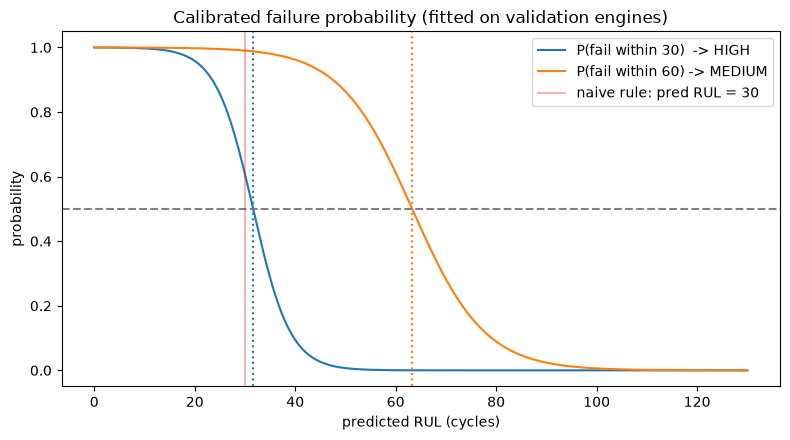

In [5]:
cal_H, cal_2H = fit_calibration(H), fit_calibration(2 * H)
cut_H, cut_2H = derived_cutoff(cal_H, P_CUT), derived_cutoff(cal_2H, P_CUT)
print(f"HIGH   when predicted RUL <= {cut_H:.1f}   (P(fail within {H}) >= {P_CUT})")
print(f"MEDIUM when predicted RUL <= {cut_2H:.1f}  (P(fail within {2*H}) >= {P_CUT})")

# Reliability check: do predicted probabilities match observed frequencies?
P_val = cal_H.predict_proba(p_val.reshape(-1, 1))[:, 1]
bins = pd.cut(P_val, [0, .1, .3, .5, .7, .9, 1.0], include_lowest=True)
rel = pd.DataFrame({"bin": bins, "predicted P": P_val, "observed": (y_val <= H)}).groupby("bin", observed=True)
print("\nReliability (validation): predicted probability vs observed share failing within H")
print(rel.agg(n=("observed", "size"), mean_predicted=("predicted P", "mean"), observed=("observed", "mean")).round(2))

grid = np.linspace(0, 130, 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(grid, cal_H.predict_proba(grid)[:, 1], label=f"P(fail within {H})  -> HIGH")
ax.plot(grid, cal_2H.predict_proba(grid)[:, 1], label=f"P(fail within {2*H}) -> MEDIUM")
ax.axhline(P_CUT, ls="--", c="grey"); ax.axvline(cut_H, ls=":", c="C0"); ax.axvline(cut_2H, ls=":", c="C1")
ax.axvline(H, ls="-", c="red", alpha=.3, label=f"naive rule: pred RUL = {H}")
ax.set_xlabel("predicted RUL (cycles)"); ax.set_ylabel("probability"); ax.legend()
ax.set_title("Calibrated failure probability (fitted on validation engines)")
plt.tight_layout(); plt.savefig("../results/failure_risk_calibration.png", dpi=150); plt.show()

**Reading:** compare the derived HIGH cut-off with the naive rule (red line at H). If the derived cut-off is
**above** H, the calibration is compensating for the model's late bias, flagging engines earlier than a naive rule would.

**Reliability table:** the bins near 0 and 1 hold most windows and match closely. In the middle bins (few windows each),
predicted probability is somewhat **higher** than observed. So the model over-states risk slightly there, which errs on the
**safe** side (earlier warnings rather than missed failures).

## 5. Evidence: sensitivity to the probability cut-off (validation, H fixed)
Lower cut-off = fewer missed failures but more false alarms. 0.5 is the neutral choice; because a missed failure is
more costly than an early inspection (NASA score is asymmetric), a lower cut-off is defensible if the client prefers safety.

In [6]:
true = y_val <= H
rows = []
for pc in [0.2, 0.3, 0.5, 0.7, 0.8]:
    flag = P_val >= pc
    rows.append({"P cut-off": pc, "derived cut-off (pred RUL)": derived_cutoff(cal_H, pc),
                 "recall": (flag & true).sum() / true.sum(), "precision": (flag & true).sum() / max(flag.sum(), 1),
                 "missed failures": int((~flag & true).sum()), "false alarms": int((flag & ~true).sum())})
pd.DataFrame(rows).round(2)

,P cut-off,derived cut-off (pred RUL),recall,precision,missed failures,false alarms
0,0.2,36.76,0.97,0.84,17,118
1,0.3,34.76,0.96,0.86,24,96
2,0.5,31.62,0.93,0.92,43,50
3,0.7,28.47,0.87,0.98,79,10
4,0.8,26.47,0.82,0.99,111,4


## 6. Apply to the test engines (used once, nothing fitted here)

In [7]:
P_H = cal_H.predict_proba(p_test.reshape(-1, 1))[:, 1]
P_2H = cal_2H.predict_proba(p_test.reshape(-1, 1))[:, 1]
level = np.where(P_H >= P_CUT, "HIGH", np.where(P_2H >= P_CUT, "MEDIUM", "LOW"))

true_band = pd.cut(y_test, [-1, H, 2 * H, np.inf], labels=[f"true <= {H}", f"{H} < true <= {2*H}", f"true > {2*H}"])
print("Risk level vs true remaining life (test, 100 engines):")
print(pd.crosstab(pd.Series(level, name="risk level"), pd.Series(true_band, name="true RUL")).reindex(["HIGH", "MEDIUM", "LOW"]))

hi, true = level == "HIGH", y_test <= H
print(f"\nHIGH vs truly failing within {H}: recall {(hi & true).sum()}/{true.sum()} = {(hi & true).sum()/true.sum():.2f}, "
      f"precision {(hi & true).sum()}/{hi.sum()} = {(hi & true).sum()/max(hi.sum(),1):.2f}")
missed = np.where(true & (level == "LOW"))[0]
print("Engines failing within H but rated LOW (dangerous misses):", [int(i) + 1 for i in missed] or "none")

Risk level vs true remaining life (test, 100 engines):


true RUL    true <= 30  30 < true <= 60  true > 60
risk level                                        
HIGH                23                1          0
MEDIUM               2                6          2
LOW                  0                7         59

HIGH vs truly failing within 30: recall 23/25 = 0.92, precision 23/24 = 0.96
Engines failing within H but rated LOW (dangerous misses): none


**Reading:** check (1) recall of HIGH against engines truly failing within H, (2) whether any engine failing within H was rated
**LOW** (the dangerous miss, since MEDIUM still triggers planning), and (3) how many LOW engines actually had H to 2H cycles left
(late MEDIUM warnings). Because the test set has only about 25 positives, quote these as counts ("23 of 25"), not just percentages.

## 7. Final per-engine table (risk + SHAP drivers) for the dashboard

In [8]:
out = pd.DataFrame({"engine": np.arange(1, len(y_test) + 1), "pred_RUL": p_test.round(1),
                    f"P_fail_{H}": P_H.round(3), f"P_fail_{2*H}": P_2H.round(3),
                    "risk_level": level, "true_RUL": y_test.astype(int)})
try:
    drivers = pd.read_csv("../results/shap_top_drivers_xgb.csv")[["engine", "driver1", "driver2", "driver3"]]
    out = out.merge(drivers, on="engine", how="left")
except FileNotFoundError:
    print("run 04_shap first to add SHAP drivers")
out.to_csv("../results/failure_risk_xgb.csv", index=False)
out.sort_values(f"P_fail_{H}", ascending=False).head(12)

,engine,pred_RUL,P_fail_30,P_fail_60,risk_level,true_RUL,driver1,driver2,driver3
67,68,7.000000,0.999,1.000,HIGH,8,s3_mean,s11_slope,s11_max
33,34,7.200000,0.999,1.000,HIGH,7,s3_mean,s11_slope,s11_max
30,31,9.100000,0.998,0.999,HIGH,8,s3_mean,s11_slope,s11_max
81,82,8.300000,0.998,1.000,HIGH,9,s3_mean,s11_slope,s11_max
80,81,8.300000,0.998,1.000,HIGH,8,s3_mean,s11_slope,s11_max
75,76,8.000000,0.998,1.000,HIGH,10,s3_mean,s11_slope,s11_max
19,20,11.100000,0.996,0.999,HIGH,16,s3_mean,s11_slope,s11_max
41,42,12.200000,0.995,0.999,HIGH,10,s3_mean,s11_slope,s11_max
48,49,12.600000,0.994,0.999,HIGH,21,s3_mean,s11_slope,s11_max
55,56,16.799999,0.982,0.998,HIGH,15,s3_mean,s11_max,s11_slope


## 8. Limitations (state these before you are asked)
- **Small test set near failure:** only the engines in the `true <= H` row of Section 6 support the test recall, so one engine changes it by several percentage points.
- **Validation windows are correlated:** they come from only 20 engines (consecutive windows overlap), so the calibration is less certain than the window count suggests.
- **Single model and seed:** calibration is specific to this XGBoost run, so re-fit it if the model changes.
- **H is an operational choice:** the data shows which horizons the model can resolve (Sections 2-3), but the final H should match how much warning maintenance planning really needs.
- **FD001 only:** one operating condition and one fault mode, so thresholds should not be assumed to transfer to FD002-FD004.